### __Anna Kaczyńska, Kamila Mosińska__
## PROJECT 4: Stochastic analysis of an aquifer tracer test
-----

### ABSTRACT


### INTRODUCTION

----------------

## Part 1

At each time step, the particle can move according to three option: move to the right with probability $p_+$ and displacement $+ \Delta x$, move to the left with probability $p_-$ and displacement $- \Delta x$ and stay with probability $1 - p_+ - p_-$. 

So $Y$ is a random variable with the following possible values:
$$
Y=
\begin{cases}
+\Delta x & \text{with probability }p_+\\
-\Delta x & \text{with probability }p_-\\
0 & \text{with probability }1-p_+-p_-
\end{cases}
$$

The mean displacement in one step is calculated as follows:
$$
\mathbb{E}[Y] = (+ \Delta x) \cdot p_+ + (- \Delta  x) \cdot p_- + 0 \cdot (1 - p_+ - p_-) = (p_+ - p_-)\Delta x.
$$

Since $t = n\Delta t$, the mean velocity of the particle is given by:
$$
v = \frac{s}{t} = \frac{n \cdot \mathbb{E}[Y]}{n\Delta t} = \frac{(p_+ - p_-)\Delta x}{\Delta t}.
$$

To be able to determine the equation for D, we start with calculating the variance of one step:
$$
Var[Y] = \mathbb{E}[Y^2] - \mathbb{E}[Y]^2 = [(\Delta x)^2 p_+ + (- \Delta x)^2 p_-] - [(p_+ - p_-)\Delta x]^2 = (p_+ + p_-)\Delta x - (p_+ - p_-)^2 \Delta x^2 = [p_+ + p_- - (p_+ - p_-)^2] \Delta x^2.
$$

Since steps are independent, the variance after n steps is equal to:
$$
Var(X_n) = nVar(Y),
$$
and
$$
Var(X_n) = n[p_+ + p_- - (p_+ - p_-)^2] \Delta x^2 = \frac{t}{\Delta t}[p_+ + p_- - (p_+ - p_-)^2] \Delta x^2 .
$$

For an instantaneous release at x=0, the analytical solution is a Gaussian distribution:
$$
C(x,t)=\frac{M}{\sqrt{4\pi Dt}}
\exp\left(-\frac{x^2}{4Dt}\right).
$$

When we compare the exponential part with the standard form of a normal distribution, we get:
$$
\sigma^2 = 2Dt.
$$

Since variance for normal distribution is equal to $\sigma^2$, we get:
$$
Var(X(t)) = 2Dt.
$$

After some transformations, we get:
$$
D = \frac{Var(X(t))}{2t} = \frac{\frac{t}{\Delta t}[p_+ + p_- - (p_+ - p_-)^2] \Delta x^2}{2t} = \frac{[p_+ + p_- - (p_+ - p_-)^2] \Delta x^2 }{2 \Delta t}.
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, probplot
import pandas as pd

In [2]:
class Solver:
    def __init__(self, x0, t0, v=0.5, D=1, alpha_L=2, lamb=0.002, M=1000, L1=50, L2=500):
        self.x0 = x0
        self.t0 = t0
        self.v = v
        self.D = D
        self.alpha_L = alpha_L
        self.lamb = lamb
        self.M = M
        self.L1 = L1
        self.L2 = L2

    def random_walk_1d(self, dt, number_of_steps, N = 20000, decay=True):
        p_decay = 1 - np.exp(-self.lamb*dt)

        trajectories = np.zeros((N, number_of_steps + 1))
        trajectories[:, 0] = self.x0
        alive = np.ones(N, dtype=bool)

        # checkpoint
        alive_count = np.zeros(number_of_steps + 1, dtype=int)
        alive_count[0] = N

        for i in range(number_of_steps):
            random_steps = np.random.normal(0, 1, N)
            trajectories[alive, i+1] = (trajectories[alive, i] + self.v * dt + np.sqrt(2 * self.D * dt) * random_steps[alive])

            if decay:
                decay_events = np.random.random(N) < p_decay
                alive = alive & ~decay_events
            
            trajectories[~alive, i+1] = np.nan

            alive_count[i+1] = np.sum(alive)
            
        return trajectories, alive_count

    def concentration_profile(self, trajectories, N, dt, time_points, bins=100, x_range=(0, 500)):
        profiles = {}

        bin_edges = np.linspace(x_range[0], x_range[1], bins+1)
        bin_centers = (bin_edges[:-1]  + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        for t in time_points:
            step = int(t/dt)
            positions = trajectories[:, step]
            positions = positions[~np.isnan(positions)]

            counts, _ = np.histogram(positions, bins=bin_edges)

            C = (self.M/N) * counts / bin_width
            profiles[t] = C

        return bin_centers, profiles

    def concentration_ananlytical(self, x, t):
        C = (self.M / np.sqrt(4*np.pi*self.D*t)) * np.exp(-((x - self.v*t)**2)/(4*self.D*t) - self.lamb*t)
        return C

    def first_arrival_times(self, trajectories, dt):
        L1 = self.L1

        previous = trajectories[:, :-1]
        current = trajectories[:, 1:]

        crossed = (previous < L1) & (current > L1)
        arrived = np.any(crossed, axis=1)
        first_cross = np.argmax(crossed, axis=1)

        arrival_times = np.full(trajectories.shape[0], np.nan)
        arrival_times[arrived] = (first_cross[arrived] + 1) * dt

        return arrival_times

    def first_arrival_analytical(self, t):
        L1 = self.L1
        f = L1/(np.sqrt(4*np.pi*self.D*t**3)) * np.exp(-((L1-self.v*t)**2)/(4*self.D*t))
        return f

In [3]:
def plot_particle_position(trajectories, dt, times=[40, 120, 300]):

    plt.figure(figsize=(10, 5))

    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for t, color in zip(times, colors):

        step = int(t / dt)
        positions = trajectories[:, step]

        positions = positions[~np.isnan(positions)]
        y = np.random.uniform(0, 1, len(positions))

        plt.scatter(
            positions,
            y,
            s=2,
            alpha=0.4,
            color=color,
            label=f't = {t} days'
        )

    plt.axvline(50, color='red', linestyle='--')

    plt.xlabel('x [m]')
    plt.legend()
    plt.tight_layout()
    plt.show()

Initial number of particles: 20000
Surviving particles: 11010
Decayed particles: 8990
Percentage decayed: 44.95%


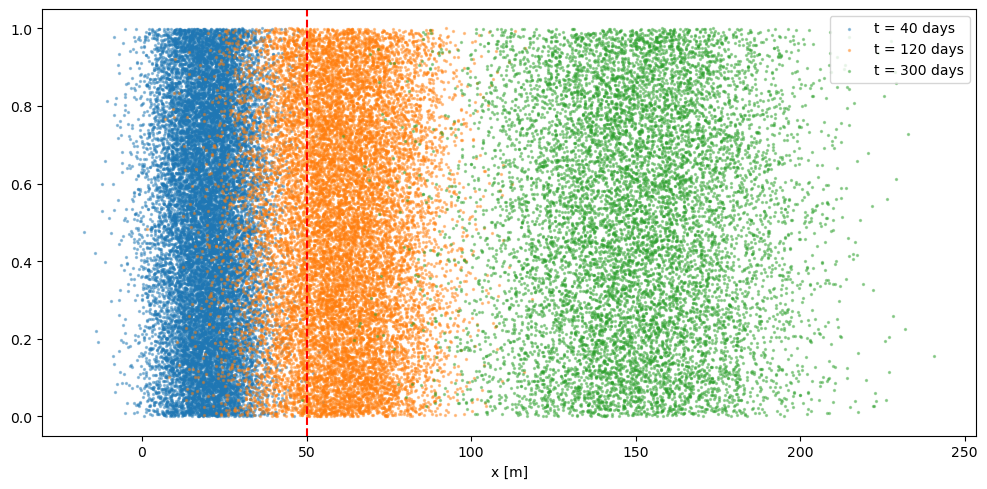

In [4]:
dt = 0.5
number_of_steps = 600  # 300 days
N = 20000

solver = Solver(x0=0, t0=0)

trajectories, alive_count = solver.random_walk_1d(
    dt=dt,
    number_of_steps=number_of_steps,
    N=N
)

print(f"Initial number of particles: {N}")
print(f"Surviving particles: {alive_count[-1]}")
print(f"Decayed particles: {N - alive_count[-1]}")
print(f"Percentage decayed: {(N - alive_count[-1]) / N * 100:.2f}%")

plot_particle_position(trajectories, dt)

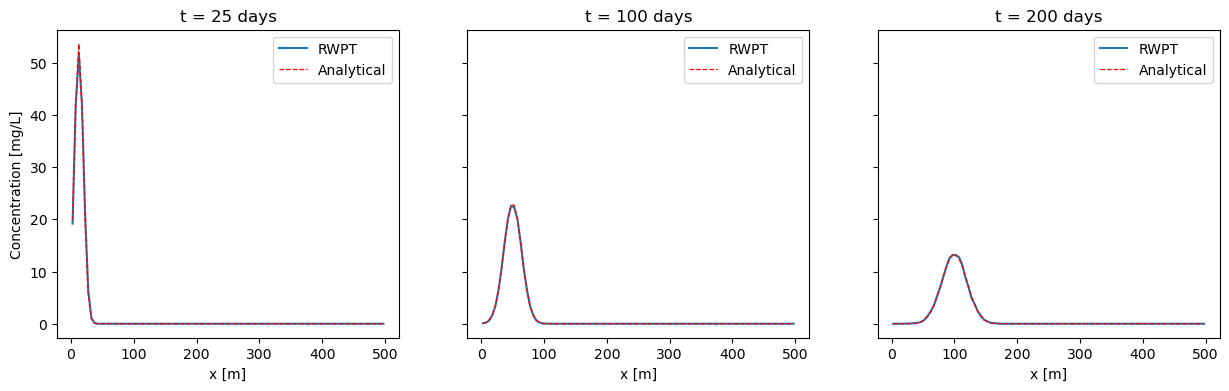

In [5]:
time_points = [25, 100, 200]

x, profiles = solver.concentration_profile(
    trajectories=trajectories,
    N=N,
    dt=dt,
    time_points=time_points,
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, t in zip(axes,time_points):
    ax.plot(x, profiles[t], label="RWPT", color="tab:blue")

    C_analytical = solver.concentration_ananlytical(x, t)
    ax.plot(x, C_analytical, "--", linewidth=0.9, label="Analytical", color="red")

    ax.set_title(f"t = {t} days")
    ax.set_xlabel("x [m]")
    ax.legend()

axes[0].set_ylabel("Concentration [mg/L]")
plt.show()

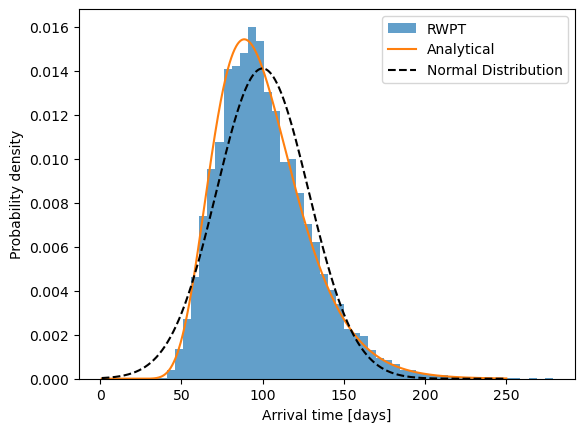

In [6]:
trajectories_no_decay, _ = solver.random_walk_1d(dt=0.5, number_of_steps=600, N=20000, decay=False)

arrival_times = solver.first_arrival_times(trajectories_no_decay, dt)
valid_arrivals = arrival_times[~np.isnan(arrival_times)]

t = np.linspace(1, 250, 1000)
f_analytical = solver.first_arrival_analytical(t)

mean = solver.L1 / solver.v
variance = 2 * solver.D * solver.L1 / solver.v**3
std = np.sqrt(variance)
normal_distribution = norm.pdf(t, mean, std)

plt.figure()
plt.hist(valid_arrivals, bins=50, density=True, alpha=0.7, label="RWPT")
plt.plot(t, f_analytical, label="Analytical")
plt.plot(t, normal_distribution, linestyle='--', color="black", label="Normal Distribution")
plt.xlabel("Arrival time [days]")
plt.ylabel("Probability density")
plt.legend()
plt.show()

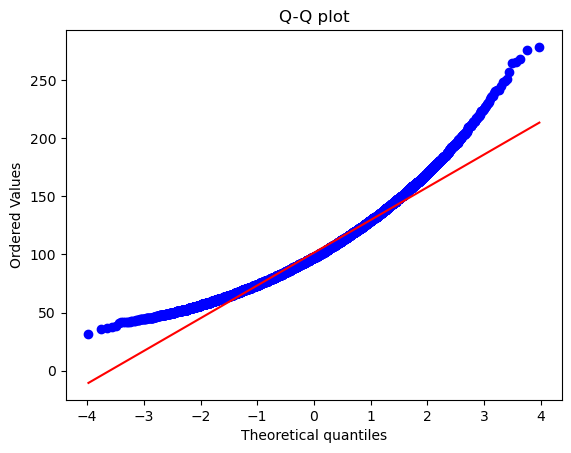

In [7]:
plt.figure()
probplot(valid_arrivals, dist="norm", plot=plt)
plt.title("Q-Q plot")
plt.show()

Based on the Q-Q plot above, we can say that arrival time does not follow normal distribution.

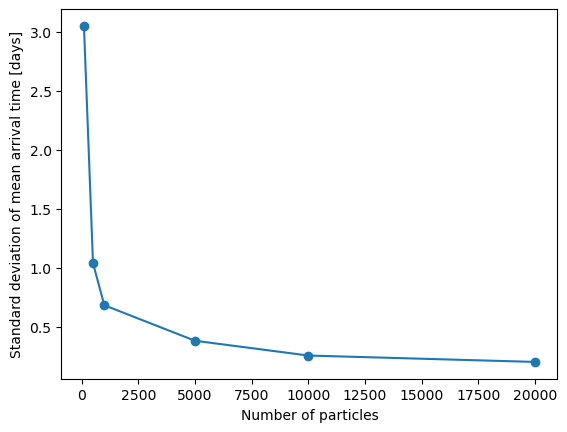

In [8]:
Ns = [100, 500, 1000, 5000, 10000, 20000]
repeats = 20
errors = []

for N in Ns:
    means = []
    for _ in range(repeats):
        traj, _ = solver.random_walk_1d(dt=0.5, number_of_steps=600, N=N, decay=False)
        arrivals = solver.first_arrival_times(traj, 0.5)
        means.append(np.nanmean(arrivals))
    errors.append(np.std(means))

plt.figure()
plt.plot(Ns, errors, "o-")
plt.xlabel("Number of particles")
plt.ylabel("Standard deviation of mean arrival time [days]")
plt.show()

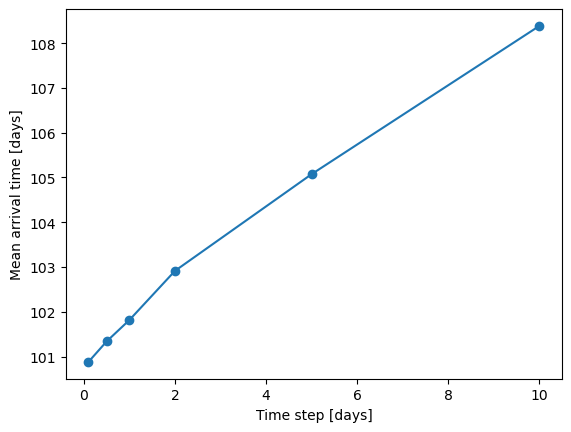

In [9]:
dts = np.array([0.1, 0.5, 1, 2, 5, 10])
N = 20000
mean_arrivals = []

for dt in dts:
    traj, _ = solver.random_walk_1d(dt=dt, number_of_steps=int(600/dt), N=N, decay=False)
    arrivals = solver.first_arrival_times(traj, dt)
    mean_arrivals.append(np.nanmean(arrivals))

plt.figure()
plt.plot(dts, mean_arrivals, "o-")
plt.xlabel("Time step [days]")
plt.ylabel("Mean arrival time [days]")
plt.show()

The mean arrival time is biased for large $\Delta t$ because the crossing condition compares the particle's positions at two consecutive time steps. Therefore, larger time steps result in less precise estimates of the arrival times. For large $N$, the statistical error becomes smaller, as it decreases approximately as $\frac{1}{\sqrt(N)}$, and the time-step bias becomes the dominant error.

### Discussion

RWPT is useful when the aquifer is heterogeneous, meaning that its properties vary in space, because particle movement can be adjusted depending on the local conditions. It is also a good choice when modelling sharp concentration fronts, as it avoids the numerical spreading that can occur in grid-based methods. However, RWPT can require a large number of particles to obtain accurate results, which increases computational cost. Grid-based methods can be faster and more efficient when a concentration field over the entire domain is needed. Therefore, RWPT is often preferable for complex problems where numerical dispersion should be minimized, while grid-based methods may be more suitable for simpler problems where computational efficiency is important.

## Part 2

The Eq. 2 from the project is:
$$
C(x,t)=\frac{M}{\sqrt{4\pi Dt}}
\exp\left(-\frac{(x-vt)^2}{4Dt} - \lambda t\right).
$$

After substituting $x=L_2$ and $t = L_2/v$, we get:
$$
C(L_2, L_2/v)=\frac{M}{\sqrt{4\pi D (\frac{L_2}{v})}}
\exp\left(-\frac{(L_2-v\frac{L_2}{v})^2}{4D\frac{L_2}{v}} - \lambda \frac{L_2}{v}\right) = \frac{M}{\sqrt{4\pi D (\frac{L_2}{v})}}
\exp\left(-\frac{\lambda L_2}{v}\right).
$$

We substitute $D=\alpha_L v$ and get:
$$
C_{peak} = \frac{M}{\sqrt{4\pi \alpha_L v (\frac{L_2}{v})}}
\exp\left(-\frac{\lambda L_2}{v}\right) = \frac{M}{\sqrt{4\pi \alpha_L L_2}}
\exp\left(-\frac{\lambda L_2}{v}\right)
$$

In [10]:
def sample_parameters(N):
    v = np.random.lognormal(mean=np.log(0.5), sigma=0.3, size=N)
    alpha_L = np.random.lognormal(mean=np.log(2), sigma=0.5, size=N)
    lamb = np.random.lognormal(mean=np.log(2*10**(-3)), sigma=0.3, size=N)
    return v, alpha_L, lamb

def calculate_peak_concentration(v, alpha_L, lamb, M, L2):
    C_peak = (M / np.sqrt(4 * np.pi * alpha_L * L2)) * np.exp(-lamb * L2 / v)
    return C_peak

In [11]:
N_values = [10**3, 10**4, 10**5, 10**6]
C_lim = 7.0

results = []
for N in N_values:

    v, alpha_L, lamb = sample_parameters(N)
    C_peak = calculate_peak_concentration(v, alpha_L, lamb, M=solver.M, L2=solver.L2)

    failures = C_peak > C_lim
    N_fail = np.sum(failures)

    P_f = N_fail/N

    SE = np.sqrt(P_f * (1 - P_f) / N)
    RSE = SE / P_f if P_f > 0 else np.inf

    CI_lower = P_f - 1.96 * SE
    CI_upper = P_f + 1.96 * SE

    CI_lower = max(0, CI_lower)
    CI_upper = min(1, CI_upper)

    results.append({
        "N": N,
        "Failures": N_fail,
        "P_f": P_f,
        "SE": SE,
        "RSE": RSE,
        "CI_lower": CI_lower,
        "CI_upper": CI_upper
    })

results_df = pd.DataFrame(results)

print(results_df)

         N  Failures       P_f        SE       RSE  CI_lower  CI_upper
0     1000         0  0.000000  0.000000       inf  0.000000  0.000000
1    10000        10  0.001000  0.000316  0.316070  0.000381  0.001619
2   100000        87  0.000870  0.000093  0.107165  0.000687  0.001053
3  1000000       887  0.000887  0.000030  0.033562  0.000829  0.000945


In [12]:
P_f_est = results_df.iloc[-1]["P_f"]

if P_f_est > 0:
    N_required = (1 - P_f_est) / (P_f_est * 0.1**2)

    print(f"Estimated failure probability: {P_f_est:.6f}")
    print(f"Required samples for 10% RSE: {N_required:.0f}")
else:
    print("No failures were observed. Cannot estimate required sample size.")

Estimated failure probability: 0.000887
Required samples for 10% RSE: 112640


In [27]:
def midpoint_rule(n, M, L2=solver.L2, C_lim=7):
    # integration domain
    lower_bound = -5
    upper_bound = 5

    # midpoints
    dz = (upper_bound - lower_bound) / n
    z = lower_bound + (np.arange(n) + 0.5) * dz

    # standard normal pdf
    phi = norm.pdf(z)

    # standard normal variables
    v = np.exp(np.log(0.5) + 0.3 * z)
    alpha_L = np.exp(np.log(2) + 0.5 * z)
    lamb = np.exp(np.log(2e-3) + 0.3 * z)

    V, A, LAM = np.meshgrid(v, alpha_L, lamb, indexing='ij')

    C_peak = calculate_peak_concentration(V, A, LAM, M=M, L2=L2)

    indicator = C_peak > C_lim
    weights = (
        phi[:, None, None]
        * phi[None, :, None]
        * phi[None, None, :]
    )

    P_f = np.sum(indicator * weights) * dz**3

    return P_f

n = 5, points = 125, Pf = 0.00136090
n = 10, points = 1000, Pf = 0.00150271
n = 15, points = 3375, Pf = 0.00115225
n = 20, points = 8000, Pf = 0.00065615
n = 30, points = 27000, Pf = 0.00086340
n = 40, points = 64000, Pf = 0.00090685
n = 60, points = 216000, Pf = 0.00085427
n = 80, points = 512000, Pf = 0.00090237
n = 100, points = 1000000, Pf = 0.00088149
n = 150, points = 3375000, Pf = 0.00088869
n = 200, points = 8000000, Pf = 0.00087336


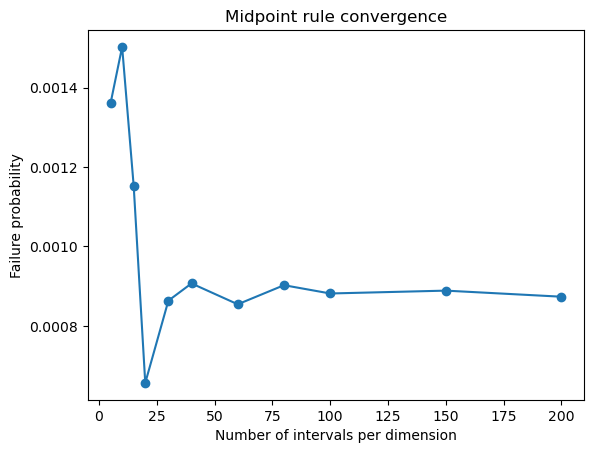

In [28]:
n_values = [5, 10, 15, 20, 30, 40, 60, 80, 100, 150, 200]

midpoint_results = []

for n in n_values:
    P_f = midpoint_rule(n, M=solver.M, L2=500)
    midpoint_results.append(P_f)

    print(f"n = {n}, points = {n**3}, Pf = {P_f:.8f}")

plt.figure()
plt.plot(n_values, midpoint_results, "o-")

plt.xlabel("Number of intervals per dimension")
plt.ylabel("Failure probability")
plt.title("Midpoint rule convergence")
plt.show()

In [30]:
def gauss_hermite(n, M, L2=solver.L2, C_lim=7):
    n = int(n)
    
    nodes, weights = np.polynomial.hermite_e.hermegauss(n)
    weights = weights/np.sqrt(2*np.pi)
    v = np.exp(np.log(0.5) + 0.3 * nodes)
    lamb = np.exp(np.log(2e-3) + 0.3 * nodes)

    V, LAM = np.meshgrid(v, lamb, indexing='ij')

    alpha_star = M**2 / (4 * np.pi * L2 * C_lim**2) * np.exp(-2 * LAM * L2 / V)

    conditional_Pf = norm.cdf(
        (np.log(alpha_star) - np.log(2)) / 0.5
    )

    P_f = np.sum(
        weights[:, None]
        * weights[None, :]
        * conditional_Pf 
    )

    return P_f

n = 5, points = 25, Pf = 0.0008714865
n = 10, points = 100, Pf = 0.0008797930
n = 15, points = 225, Pf = 0.0008796630
n = 20, points = 400, Pf = 0.0008796662
n = 30, points = 900, Pf = 0.0008796664
n = 40, points = 1600, Pf = 0.0008796664
n = 60, points = 3600, Pf = 0.0008796664
n = 80, points = 6400, Pf = 0.0008796664
n = 100, points = 10000, Pf = 0.0008796664
n = 150, points = 22500, Pf = 0.0008796664
n = 200, points = 40000, Pf = 0.0008796664


C:\Users\impet\AppData\Local\Temp\ipykernel_15048\3990330394.py:14: RuntimeWarning: divide by zero encountered in log
  (np.log(alpha_star) - np.log(2)) / 0.5


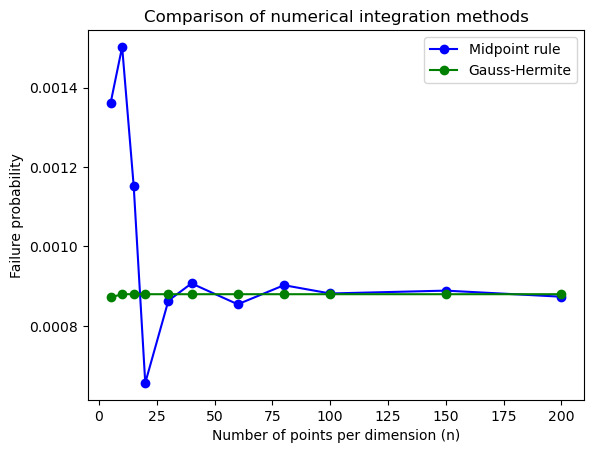

In [31]:
gh_results = []

for n in n_values:

    P_f = gauss_hermite(
        n=n,
        M=solver.M,
        L2=500
    )

    gh_results.append(P_f)

    print(f"n = {n:g}, points = {n**2:g}, Pf = {P_f:.10f}")

plt.figure()
plt.plot(n_values, midpoint_results, "o-", color="blue", label="Midpoint rule")
plt.plot(n_values, gh_results, "o-", color="green", label="Gauss-Hermite")

plt.xlabel("Number of points per dimension (n)")
plt.ylabel("Failure probability")
plt.title("Comparison of numerical integration methods")
plt.legend()
plt.show()